In [4]:
import atlite as atlite
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
from importlib import reload

reload(atlite)
# from atlite.pv.solar_position import SolarPosition


# world = gpd.read_file(gpd.datasets.get_path("naturalearth_lowres"))
# Store the file under the following locations: r"./110m_cultural/ne_110m_admin_0_countries.shp"
# and run the following lines
world = gpd.read_file(r"./110m_cultural/ne_110m_admin_0_countries.shp")
portugal = world.query('ADMIN == "Portugal"')

Text(0.5, 1.0, 'PV Huld')

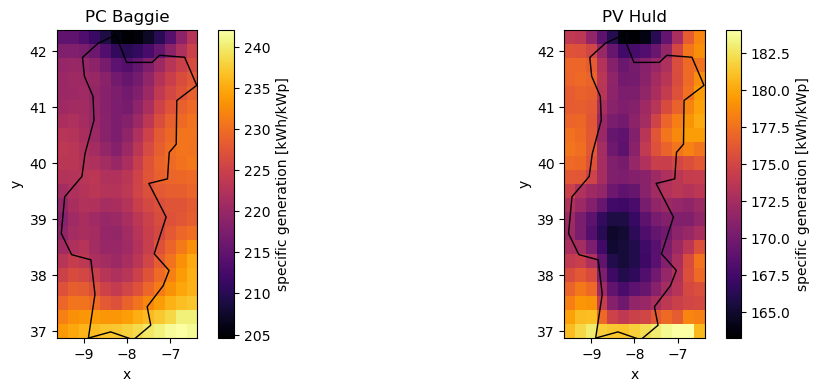

In [6]:
# cutout = atlite.Cutout(
#     path="port-era5-2019-05.nc",
#     module="era5",
#     bounds=portugal.iloc[0].geometry.bounds,
#     time="2019-05",
# )

# cutout.prepare(features=["influx", "temperature"])

cutout = atlite.Cutout(path="./port-era5-2019-05.nc")
# cutout = atlite.Cutout(path="./eur-era5-2019-05.nc")


# Prepare photovoltaic capacity factors
cf_pv = cutout.pv(
    panel="CSi",
    orientation={"slope": 30.0, "azimuth": 180.0},
    tracking=None,
)

# Prepare photocatalysis (panel) capacity factors
cf_pc_baggie = cutout.photocatalysis(
    panel="baggie", orientation={"slope": 0.0, "azimuth": 180.0}, tracking=None
)


# Plot capacity factor with Portugal shape overlay
fig, ax = plt.subplots(1, 2)
fig.set_size_inches(12, 4)

cf_pc_baggie.plot(cmap="inferno", ax=ax[0])
portugal.plot(fc="None", ec="black", ax=ax[0])
ax[0].set_title("PC Baggie")

cf_pv.plot(cmap="inferno", ax=ax[1])
portugal.plot(fc="None", ec="black", ax=ax[1])
ax[1].set_title("PV Huld")

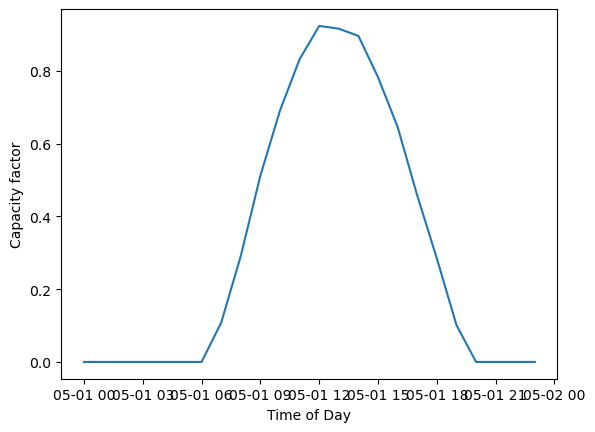

In [7]:
# Plot one day  (this party is like in "solarpv_tracking_options.ipynb")

cf_pc_2 = cutout.photocatalysis(
    panel="baggie",
    orientation={"slope":0.0, "azimuth": 180.0},
    shapes=cutout.grid,
    tracking=None,
    per_unit=True,
)


cells = cutout.grid
point = cells[(cells["y"] == 37.5) & (cells["x"] == -8.0)].index
day = "2019-05-01"
day_profile = cf_pc_2.loc[day, point].squeeze()

fig, ax = plt.subplots()

ax.plot(day_profile.to_series())
ax.set_xlabel("Time of Day")
ax.set_ylabel("Capacity factor")

# yearly average
average = cf_pc_2.mean("dim_0").mean().item()

Text(0.5, 0.98, 'Layout with PS10')

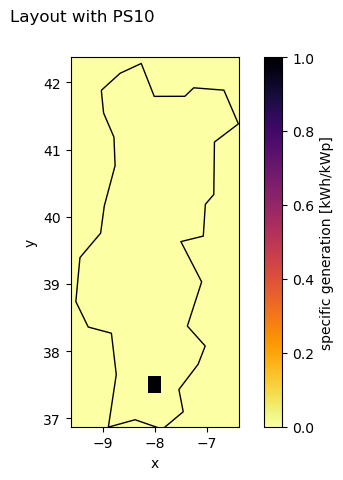

In [8]:
# This part is like in "working-with-csp.ipynb"

location = {"x": -8.0, "y": 37.442222}

# Determine location on cutout grid
nearest_location = {
    v: cutout.grid[v].iloc[cutout.grid[v].sub(location[v]).abs().idxmin()]
    for v in ["x", "y"]
}

installed_power = 1

layout = xr.zeros_like(cf_pc_baggie)
layout.loc[dict(x=nearest_location["x"], y=nearest_location["y"])] = installed_power

# Plot layout with  Spain shape overlay
fig, ax = plt.subplots()
layout.plot(cmap="inferno_r", ax=ax)
portugal.plot(fc="None", ec="black", ax=ax)
fig.suptitle("Layout with PS10")

Text(0.5, 1.0, 'Contour Plot: Irradiance vs. Temperature and Capacity Factor')

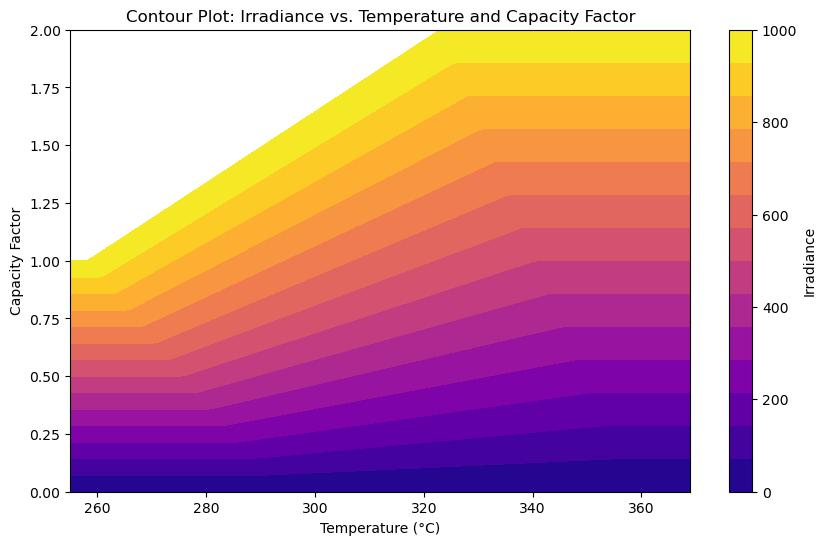

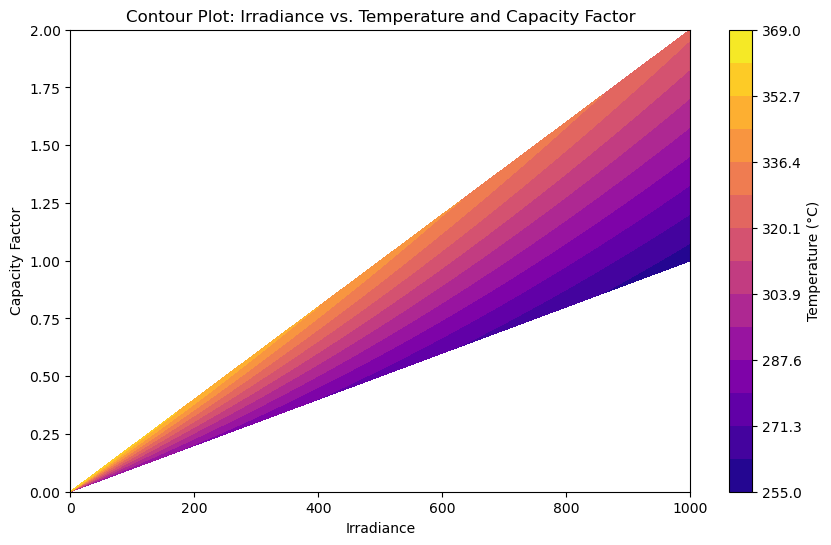

In [9]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd


def _hydrogen_flow(STH, irradiance):
    """
    Computes the hydrogen flow (kWh/s) of a PEC-Module. Assumes the module area
    to be 1 m2.

    STH: float
        Solar-to-hydrogen efficiency

    irradiance: np.array
        Irradiance (W/m2)

    Return hydrogen flow. (kW/ (m**2))
    """

    dG_r0 = 237.13e3  # (J/mol) Gibbs free energy change for water splitting at standard conditions (25°C, 1 atm)
    M_H2 = 0.002  # Molar weight of hydrogen molecule (kg/mol)
    LHV_H2 = 33.33 * 3600  # Lower heating value of hydrogen (kJ/kg)

    flow_mol_time = (STH * irradiance) / dG_r0  # (mol/(s m²))

    flow_kg_time = flow_mol_time * M_H2 * LHV_H2  # (kJ/(s m²))

    return flow_kg_time  # (kW/ (m**2))


def _flow_panel(irradiance, t_amb, pc):
    """
    Computes the energy to power ratio of a photocatalysis (PEC) module.

    Parameters
    ----------
    irradiance :
        solar irradiance for the 'ds' dataset.
        Is calculated using atlite.pv.irradiation
    t_amb :
        Ambient temperature as from the weather data

    """

    test = np.interp(
        293.15, [pc["low_Tmod"], pc["high_Tmod"]], [pc["low_STH"], pc["high_STH"]]
    )

    flow_ref = _hydrogen_flow(
        test,  # Interpolated Solar-to-Hydrogen efficiency at 25°C
        pc["r_irradiance"],  # Reference irradiance
    )  # Resulting in kWh/s

    # Calculate module temperature
    T_ = pc["c_temp_amb"] * t_amb + pc["c_temp_irrad"] * irradiance  # - pc["r_tmod"]

    # Interpolate the Solar-to-Hydrogen efficiency for the calculated module temperature
    module_STH = np.interp(
        T_, [pc["low_Tmod"], pc["high_Tmod"]], [pc["low_STH"], pc["high_STH"]]
    )

    # Calculate the hydrogen flow rate for the module temperature and irradiance
    flow = _hydrogen_flow(module_STH, irradiance)

    da = flow

    da = da / flow_ref

    return da


pc = {
    "c_temp_amb": 1,
    "c_temp_irrad": 0.035,
    "r_tamb": 293,
    "r_tmod": 298,
    "r_irradiance": 1000,
    "low_STH": 0.125,
    "high_STH": 0.25,
    "low_Tmod": 293.15,
    "high_Tmod": 358,
}


# Generate sample data for temperature and capacity factor
temperatures = np.arange(255, 370, 1)  # Temperature values on x-axis
irradiances = np.arange(0, 1000.1, 1)  # Capacity factor values on y-axis

# Create a grid of temperature and irradiance values
X, Y = np.meshgrid(temperatures, irradiances)

# Calculate capacity factor for each combination of temperature and irradiance
Z = _flow_panel(Y, X, pc)

fig, ax = plt.subplots(figsize=(10, 6))
# plt.figure(figsize=(10, 6))

# Create the contour plot
levels = np.linspace(
    np.min(Y), np.max(Y), 15
)  # Define levels for a smooth color transition
contour = ax.contourf(
    X,
    Z,
    Y,
    levels=levels,
    cmap="plasma",
    norm=Normalize(vmin=np.min(Y), vmax=np.max(Y)),
)
plt.colorbar(
    contour, label="Irradiance", ticks=np.arange(0, 1000.1, 200)
)  # Add colorbar with label

# Add labels and title
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Capacity Factor")
ax.set_title("Contour Plot: Irradiance vs. Temperature and Capacity Factor")


fig, ax = plt.subplots(figsize=(10, 6))
# plt.figure(figsize=(10, 6))

# Create the contour plot
levels = np.linspace(
    np.min(X), np.max(X), 15
)  # Define levels for a smooth color transition
contour = ax.contourf(
    Y,
    Z,
    X,
    levels=levels,
    cmap="plasma",
    norm=Normalize(vmin=np.min(X), vmax=np.max(X)),
)
plt.colorbar(contour, label="Temperature (°C)")  # Add colorbar with label

# Add labels and title
ax.set_xlabel("Irradiance")
ax.set_ylabel("Capacity Factor")
ax.set_title("Contour Plot: Irradiance vs. Temperature and Capacity Factor")

In [6]:
# def create_sample_data(
#     constant_irradiance=None,
#     temp_range=None,
#     irradiance_range=None,
#     constant_temperature=None,
# ):

#     if constant_irradiance is not None and temp_range is not None:
#         # Constant irradiance with temperature range
#         irradiation_data = np.full(500, constant_irradiance)
#         temperature_data = np.linspace(
#             temp_range[0], temp_range[1], num=np.prod(500)
#         ).reshape(500)
#     elif irradiance_range is not None and constant_temperature is not None:
#         # Irradiance range with constant temperature
#         irradiation_data = np.linspace(
#             irradiance_range[0], irradiance_range[1], num=np.prod(500)
#         ).reshape(500)
#         temperature_data = np.full(500, constant_temperature)
#     else:
#         raise ValueError(
#             "You must provide either (constant_irradiance and temp_range) or (irradiance_range and constant_temperature)."
#         )

#     return irradiation_data, temperature_data

# fig, ax = plt.subplots()
# for const_irr in np.arange(0.0,1000.1,200):
#     irradiance_1, temperature_1 = create_sample_data(
#         constant_irradiance=const_irr, temp_range=(255.0, 370.0)
#     )

#     flow_1 = _flow_panel(irradiance_1, temperature_1, pc)


#     ax.plot(temperature_1, flow_1, label=irradiance_1[0])
# ax.set_xlabel("Temperature")
# ax.set_ylabel("Capacity Factor")
# ax.set_xlim(255,None)
# ax.grid()
# ax.legend()


# fig, ax = plt.subplots()
# for const_temp in np.arange(255,370.1,15):
#     # Irradiance range with constant temperature
#     irradiance_2, temperature_2 = create_sample_data(
#         irradiance_range=(0.0, 1000.0), constant_temperature=const_temp
#     )

#     flow_2 = _flow_panel(irradiance_2, temperature_2, pc)


#     ax.plot(irradiance_2, flow_2, label=temperature_2[0])

# ax.set_xlabel("Irradiance")
# ax.set_ylabel("Capacity Factor")
# ax.grid()
# ax.legend()
# plt.show()